Preparação

In [14]:

# Bibliotecas para manipulação e análise dos dados
import numpy as np
import pandas as pd

# Ferramentas de Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

# Visualização dos resultados
import matplotlib.pyplot as plt

# Salvar o modelo treinado
import joblib

print("Bibliotecas importadas com sucesso!")


Bibliotecas importadas com sucesso!


Criação da base de dados sintéticos

In [15]:

# Reprodutibilidade: os resultados podem ser reproduzidos
np.random.seed(42)

# Quantidade de amostras
n = 5000

# Geração da base de dados sintética
df = pd.DataFrame({
    "idade_media": np.random.normal(55, 12, n).clip(18, 90),
    "carga_sistema": np.random.uniform(30, 100, n),
    "tempo_espera": np.random.normal(45, 20, n).clip(5, 180),
    "fc_media": np.random.normal(85, 15, n).clip(50, 150),
    "spo2_media": np.random.normal(95, 3, n).clip(70, 100),
    "pa_sistolica": np.random.normal(125, 20, n).clip(80, 200),
    "temperatura": np.random.normal(24, 5, n).clip(10, 40),
    "densidade_eventos": np.random.poisson(3, n),
    "eventos_24h": np.random.poisson(2, n),
    "disponibilidade_recursos": np.random.uniform(20, 100, n)
})

# Cálculo da pontuação de risco conforme o enunciado
risk_score = (
    (df["carga_sistema"] > 80).astype(int) +
    (df["tempo_espera"] > 60).astype(int) +
    (df["spo2_media"] < 92).astype(int) +
    (df["fc_media"] > 110).astype(int) +
    (df["eventos_24h"] > 4).astype(int) +
    (df["disponibilidade_recursos"] < 40).astype(int)
)

# Criação da variável que o modelo deverá prever
df["pico_risco"] = (risk_score >= 2).astype(int)

print("Base de dados criada com sucesso!")
print("Quantidade de linhas e colunas:", df.shape)
print("\nPrimeiras cinco amostras:")
display(df.head())


Base de dados criada com sucesso!
Quantidade de linhas e colunas: (5000, 11)

Primeiras cinco amostras:


,idade_media,carga_sistema,tempo_espera,fc_media,spo2_media,pa_sistolica,temperatura,densidade_eventos,eventos_24h,disponibilidade_recursos,pico_risco
0,60.960570,41.776561,26.230658,111.709579,92.960100,131.711117,25.449200,1,2,35.486591,1
1,53.340828,43.295432,34.071848,112.443439,96.509986,81.160294,18.040015,4,1,82.232538,0
2,62.772262,62.249852,39.355188,76.369939,94.709752,163.880966,19.905007,6,0,88.160917,0
3,73.276358,50.039590,66.015486,88.797755,93.714735,131.224152,28.616685,2,2,89.771810,0
4,52.190160,47.322409,21.741220,63.560997,95.784214,138.439755,33.384496,4,0,62.786630,0


Conferir base

In [16]:

# Conferir os tipos das variáveis e valores ausentes
print("Informações da base:")
df.info()

print("\nQuantidade de valores ausentes:")
print(df.isnull().sum())

print("\nDistribuição da variável pico_risco:")
print(df["pico_risco"].value_counts())

print("\nProporção de cada classe:")
print(df["pico_risco"].value_counts(normalize=True).round(3))


Informações da base:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   idade_media               5000 non-null   float64
 1   carga_sistema             5000 non-null   float64
 2   tempo_espera              5000 non-null   float64
 3   fc_media                  5000 non-null   float64
 4   spo2_media                5000 non-null   float64
 5   pa_sistolica              5000 non-null   float64
 6   temperatura               5000 non-null   float64
 7   densidade_eventos         5000 non-null   int64  
 8   eventos_24h               5000 non-null   int64  
 9   disponibilidade_recursos  5000 non-null   float64
 10  pico_risco                5000 non-null   int64  
dtypes: float64(8), int64(3)
memory usage: 429.8 KB

Quantidade de valores ausentes:
idade_media                 0
carga_sistema               0
tempo_espera

Separar dados de treino e teste

In [17]:

# Separar as variáveis de entrada e a variável-alvo
X = df.drop(columns=["pico_risco"])
y = df["pico_risco"]

# Dividir os dados em treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Conferir o resultado da divisão
print("Amostras para treino:", len(X_train))
print("Amostras para teste:", len(X_test))

print("\nDistribuição da classe no treino:")
print(y_train.value_counts(normalize=True).round(3))

print("\nDistribuição da classe no teste:")
print(y_test.value_counts(normalize=True).round(3))


Amostras para treino: 4000
Amostras para teste: 1000

Distribuição da classe no treino:
pico_risco
0    0.734
1    0.266
Name: proportion, dtype: float64

Distribuição da classe no teste:
pico_risco
0    0.734
1    0.266
Name: proportion, dtype: float64


Treino dos modelos

In [18]:

# Criar os três modelos
modelos = {
    "Regressao Logistica": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", LogisticRegression(max_iter=1000, random_state=42))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    )
}

# Treinar cada modelo com os dados de treino
for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    print(f"{nome}: treinamento concluído!")

print("\nTodos os modelos foram treinados.")


Regressao Logistica: treinamento concluído!
Random Forest: treinamento concluído!
Gradient Boosting: treinamento concluído!

Todos os modelos foram treinados.


In [19]:

# Comparar o desempenho dos modelos
resultados = []

for nome, modelo in modelos.items():
    # Previsões feitas nos dados de teste
    y_pred = modelo.predict(X_test)

    # Calcular as métricas
    resultados.append({
        "Modelo": nome,
        "Acuracia": accuracy_score(y_test, y_pred),
        "Precisao": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0)
    })

# Mostrar os resultados em uma tabela
resultados_df = pd.DataFrame(resultados)

display(
    resultados_df.round(4).sort_values(
        by="F1-score",
        ascending=False
    ).reset_index(drop=True)
)


,Modelo,Acuracia,Precisao,Recall,F1-score
0,Random Forest,0.999,1.0000,0.9962,0.9981
1,Gradient Boosting,0.998,1.0000,0.9925,0.9962
2,Regressao Logistica,0.816,0.6934,0.5526,0.6151


Criar matriz de confusão
- mostra quantos casos o modelo classificou corretamente e quantos ele confundiu
- Melhor modelo escolhido: Random Forest


Matriz de confusão:
[[734   0]
 [  1 265]]


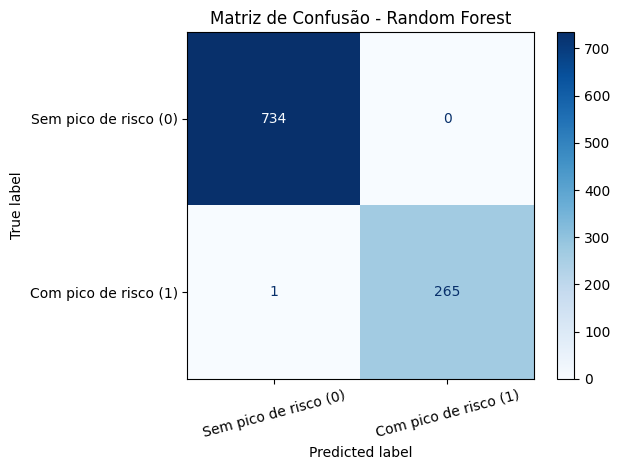


Relatório de classificação:
                   precision    recall  f1-score   support

Sem pico de risco     0.9986    1.0000    0.9993       734
Com pico de risco     1.0000    0.9962    0.9981       266

         accuracy                         0.9990      1000
        macro avg     0.9993    0.9981    0.9987      1000
     weighted avg     0.9990    0.9990    0.9990      1000



In [20]:

# Selecionar o modelo Random Forest
modelo_final = modelos["Random Forest"]

# Fazer previsões nos dados de teste
y_pred = modelo_final.predict(X_test)

# Calcular a matriz de confusão
matriz = confusion_matrix(y_test, y_pred)

print("Matriz de confusão:")
print(matriz)

# Exibir a matriz em um gráfico
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Sem pico de risco (0)", "Com pico de risco (1)"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de Confusão - Random Forest")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Relatório detalhado
print("\nRelatório de classificação:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Sem pico de risco", "Com pico de risco"],
    digits=4
))


Verificar o score de risco

In [21]:

# Probabilidades previstas para a classe 1
probabilidades = modelo_final.predict_proba(X_test)[:, 1]

print("Primeiras 10 probabilidades previstas:")
print(np.round(probabilidades[:10], 4))

print("\nMenor probabilidade:", round(probabilidades.min(), 4))
print("Maior probabilidade:", round(probabilidades.max(), 4))


Primeiras 10 probabilidades previstas:
[0.98 0.   0.02 0.99 0.01 0.77 0.99 0.08 0.98 0.  ]

Menor probabilidade: 0.0
Maior probabilidade: 1.0


Avaliação da calibração das probabilidades

Brier Score: 0.0058


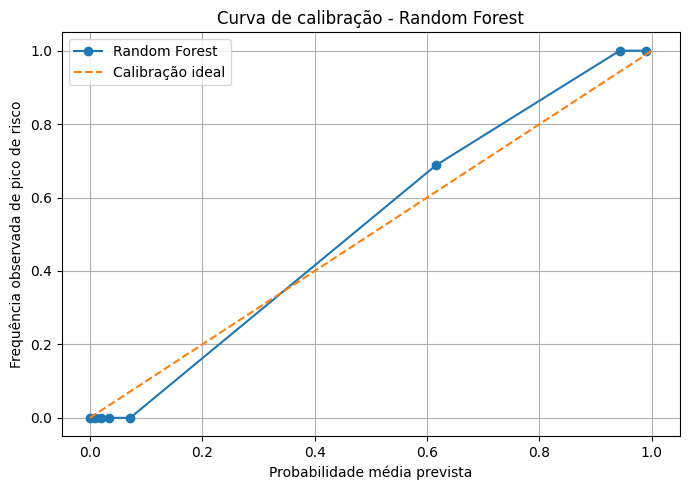

In [22]:

from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

# Probabilidades previstas para os casos de teste
probabilidades = modelo_final.predict_proba(X_test)[:, 1]

# Erro de calibração (Brier Score): quanto menor, melhor
brier = brier_score_loss(y_test, probabilidades)
print(f"Brier Score: {brier:.4f}")

# Comparação entre probabilidades previstas e frequências observadas
fracao_positiva, prob_media = calibration_curve(
    y_test,
    probabilidades,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 5))
plt.plot(prob_media, fracao_positiva, marker="o", label="Random Forest")
plt.plot([0, 1], [0, 1], linestyle="--", label="Calibração ideal")
plt.xlabel("Probabilidade média prevista")
plt.ylabel("Frequência observada de pico de risco")
plt.title("Curva de calibração - Random Forest")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Salvando o modelo treinado

In [23]:

import joblib

# Salvar o modelo treinado em um arquivo
nome_arquivo = "modelo_risco_cardiaco.joblib"
joblib.dump(modelo_final, nome_arquivo)

print(f"Modelo salvo com sucesso: {nome_arquivo}")


Modelo salvo com sucesso: modelo_risco_cardiaco.joblib


In [24]:

from google.colab import files

files.download("modelo_risco_cardiaco.joblib")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Base de conhecimento com os 10 protocolos

In [25]:

protocolos = [
    "Se SPO2 < 88% → iniciar suporte respiratório imediato",
    "Se carga do sistema > 85% → abrir unidades temporárias",
    "Se FC > 120 → iniciar monitoramento intensivo",
    "Se eventos_24h > 5 → ativar equipe de resposta rápida",
    "Se disponibilidade_recursos < 30% → redistribuir insumos",
    "Se tempo_espera > 90 min → priorizar triagem emergencial",
    "Se temperatura > 38°C média → iniciar protocolo infeccioso",
    "Se densidade_eventos > 6 → ativar plano de contingência",
    "Se PA sistólica < 90 → iniciar protocolo de choque",
    "Se risco sistêmico alto → ativar estado de emergência"
]

print("BASE DE CONHECIMENTO — PROTOCOLOS")
for i, protocolo in enumerate(protocolos, start=1):
    print(f"{i}. {protocolo}")

print(f"\nTotal de protocolos: {len(protocolos)}")


BASE DE CONHECIMENTO — PROTOCOLOS
1. Se SPO2 < 88% → iniciar suporte respiratório imediato
2. Se carga do sistema > 85% → abrir unidades temporárias
3. Se FC > 120 → iniciar monitoramento intensivo
4. Se eventos_24h > 5 → ativar equipe de resposta rápida
5. Se disponibilidade_recursos < 30% → redistribuir insumos
6. Se tempo_espera > 90 min → priorizar triagem emergencial
7. Se temperatura > 38°C média → iniciar protocolo infeccioso
8. Se densidade_eventos > 6 → ativar plano de contingência
9. Se PA sistólica < 90 → iniciar protocolo de choque
10. Se risco sistêmico alto → ativar estado de emergência

Total de protocolos: 10


Testar o modelo

In [26]:

import joblib
import pandas as pd

# Carregar o modelo salvo
modelo_carregado = joblib.load("modelo_risco_cardiaco.joblib")

# Criar um caso sintético para teste
novo_caso = pd.DataFrame([{
    "idade_media": 62,
    "carga_sistema": 92,
    "tempo_espera": 75,
    "fc_media": 118,
    "spo2_media": 89,
    "pa_sistolica": 100,
    "temperatura": 37.5,
    "densidade_eventos": 7,
    "eventos_24h": 5,
    "disponibilidade_recursos": 25
}])

# Obter a previsão
classe = modelo_carregado.predict(novo_caso)[0]
score = modelo_carregado.predict_proba(novo_caso)[0, 1]

print("Classe prevista:", classe)
print(f"Score estimado pelo modelo: {score:.2f}")


Classe prevista: 1
Score estimado pelo modelo: 0.96
